In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Load dataset
data_path = Path("merged_orders_cleaned.csv")
df = pd.read_csv(data_path)

# Parse order date
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1500, 17)


,Order ID,Order Date,CustomerName,State,City,Amount,Profit,Quantity,Category,Sub-Category,Year,Month,Month_Name,Quarter,Day,Weekday,Weekday_Name
0,B-25601,2018-04-01,Bharat,Gujarat,Ahmedabad,1275.0,-1148.0,7,Furniture,Bookcases,2018,4,Apr,2,1,6,Sunday
1,B-25601,2018-04-01,Bharat,Gujarat,Ahmedabad,66.0,-12.0,5,Clothing,Stole,2018,4,Apr,2,1,6,Sunday
2,B-25601,2018-04-01,Bharat,Gujarat,Ahmedabad,8.0,-2.0,3,Clothing,Hankerchief,2018,4,Apr,2,1,6,Sunday
3,B-25601,2018-04-01,Bharat,Gujarat,Ahmedabad,80.0,-56.0,4,Electronics,Electronic Games,2018,4,Apr,2,1,6,Sunday
4,B-25602,2018-04-01,Pearl,Maharashtra,Pune,168.0,-111.0,2,Electronics,Phones,2018,4,Apr,2,1,6,Sunday


In [3]:
import pandas as pd
import numpy as np

# Calculate business metrics
total_sales = df["Amount"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity"].sum()
unique_orders = df["Order ID"].nunique()
average_order_value = total_sales / unique_orders if unique_orders else 0

# Create overview table
overview = pd.DataFrame({
    "Metric": [
        "Total Sales",
        "Total Profit",
        "Total Quantity",
        "Unique Orders",
        "Average Sales per Order"
    ],
    "Value": [
        total_sales,
        total_profit,
        total_quantity,
        unique_orders,
        average_order_value
    ]
})

display(overview)

,Metric,Value
0,Total Sales,431502.000
1,Total Profit,23955.000
2,Total Quantity,5615.000
3,Unique Orders,500.000
4,Average Sales per Order,863.004


In [4]:
category_summary = (
    df.groupby("Category", as_index=False)
      .agg(
          Total_Sales=("Amount", "sum"),
          Total_Profit=("Profit", "sum"),
          Total_Quantity=("Quantity", "sum"),
          Line_Items=("Order ID", "size")
      )
)

category_summary["Profit_Margin_%"] = (
    category_summary["Total_Profit"]
    / category_summary["Total_Sales"] * 100
)

display(
    category_summary.sort_values(
        "Total_Sales", ascending=False
    ).round(2)
)

,Category,Total_Sales,Total_Profit,Total_Quantity,Line_Items,Profit_Margin_%
1,Electronics,165267.0,10494.0,1154,308,6.35
0,Clothing,139054.0,11163.0,3516,949,8.03
2,Furniture,127181.0,2298.0,945,243,1.81


In [5]:
# Sub-category performance
subcategory_summary = (
    df.groupby(["Category", "Sub-Category"], as_index=False)
      .agg(
          Total_Sales=("Amount", "sum"),
          Total_Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum")
      )
)

subcategory_summary["Profit_Margin_%"] = (
    subcategory_summary["Total_Profit"]
    / subcategory_summary["Total_Sales"] * 100
)

display(
    subcategory_summary.sort_values(
        "Total_Profit"
    ).round(2)
)

,Category,Sub-Category,Total_Sales,Total_Profit,Quantity,Profit_Margin_%
16,Furniture,Tables,22614.0,-4011.0,61,-17.74
10,Electronics,Electronic Games,39168.0,-1236.0,297,-3.16
1,Clothing,Kurti,3361.0,181.0,164,5.39
5,Clothing,Skirt,1946.0,235.0,248,12.08
2,Clothing,Leggings,2106.0,260.0,186,12.35
3,Clothing,Saree,53511.0,352.0,782,0.66
14,Furniture,Chairs,34222.0,577.0,277,1.69
15,Furniture,Furnishings,13484.0,844.0,310,6.26
4,Clothing,Shirt,7555.0,1131.0,271,14.97
7,Clothing,T-shirt,7382.0,1500.0,305,20.32


In [6]:
state_summary = (
    df.groupby("State", as_index=False)
      .agg(
          Total_Sales=("Amount", "sum"),
          Total_Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum")
      )
)

state_summary["Profit_Margin_%"] = (
    state_summary["Total_Profit"]
    / state_summary["Total_Sales"] * 100
)

display(state_summary.sort_values("Total_Profit").round(2))

,State,Total_Sales,Total_Profit,Quantity,Profit_Margin_%
16,Tamil Nadu,6087.0,-2216.0,91,-36.41
13,Punjab,16786.0,-609.0,216,-3.63
0,Andhra Pradesh,13256.0,-496.0,146,-3.74
1,Bihar,12943.0,-321.0,206,-2.48
7,Jammu and Kashmir,10829.0,8.0,177,0.07
12,Nagaland,11903.0,148.0,173,1.24
3,Goa,6705.0,370.0,145,5.52
15,Sikkim,5276.0,401.0,93,7.60
4,Gujarat,21058.0,465.0,328,2.21
8,Karnataka,15058.0,645.0,180,4.28


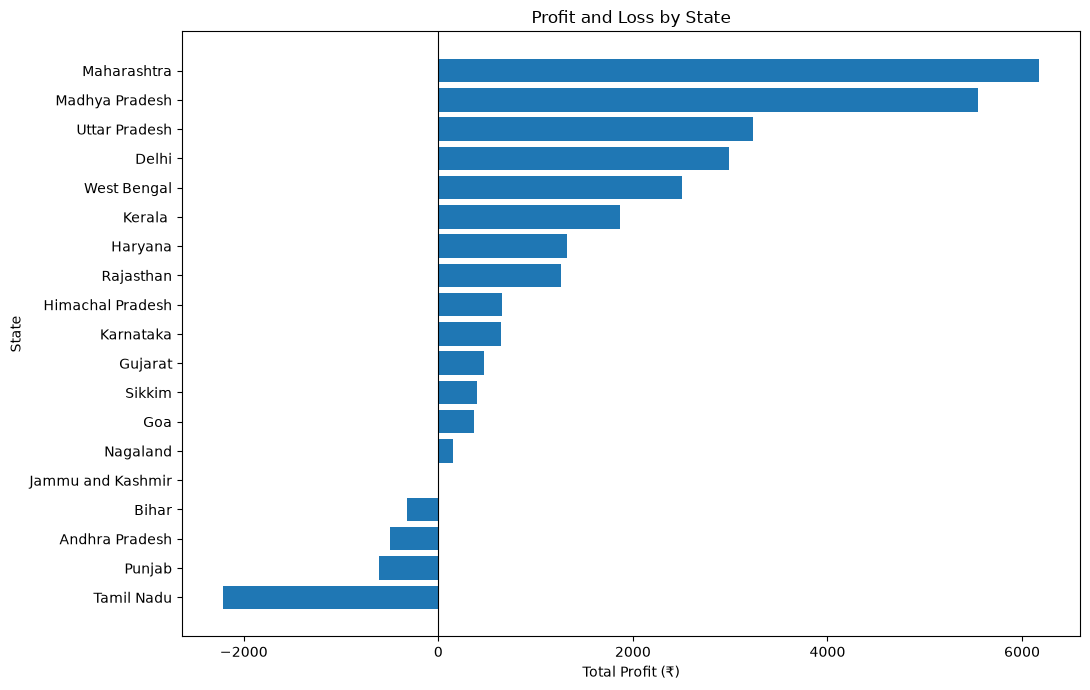

In [7]:
# Visualize state-wise profit and loss
state_profit = state_summary.sort_values("Total_Profit")

plt.figure(figsize=(11, 7))
plt.barh(
    state_profit["State"],
    state_profit["Total_Profit"]
)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Profit and Loss by State")
plt.xlabel("Total Profit (₹)")
plt.ylabel("State")
plt.tight_layout()
plt.show()

## AI-Powered Business Questions Using PandasAI

In [23]:
import pandasai
print(pandasai.__version__)

<module 'pandasai.__version__' from 'c:\\Users\\DELL\\Desktop\\Cynaris-Internship\\Week 5\\.venv\\Lib\\site-packages\\pandasai\\__version__.py'>


In [24]:
from importlib.metadata import version

print("PandasAI version:", version("pandasai"))

PandasAI version: 3.0.0


In [25]:
import os

print("OpenAI API key available:", bool(os.getenv("OPENAI_API_KEY")))

OpenAI API key available: False


In [26]:
from pathlib import Path

env_path = Path(".env")
print("Found .env:", env_path.exists())

Found .env: True


In [27]:
%pip install python-dotenv

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [28]:
import os
from dotenv import load_dotenv

load_dotenv(".env")

api_key = os.getenv("OPENAI_API_KEY")

print("API key loaded:", bool(api_key))

API key loaded: False


In [29]:
import os
from dotenv import load_dotenv

load_dotenv(".env", override=True)

api_key = os.getenv("OPENAI_API_KEY")

print("API key loaded:", bool(api_key))

API key loaded: False


In [30]:
from pathlib import Path

env_file = Path(".env")

if env_file.exists():
    names = []
    for line in env_file.read_text().splitlines():
        line = line.strip()
        if line and not line.startswith("#") and "=" in line:
            names.append(line.split("=", 1)[0].strip())

    print("Variable names in .env:", names)
else:
    print(".env file not found")

Variable names in .env: ['GEMINI_API_KEY']


In [31]:
import os
from dotenv import load_dotenv

load_dotenv(".env", override=True)

gemini_key = os.getenv("GEMINI_API_KEY")
print("Gemini key loaded:", bool(gemini_key))

Gemini key loaded: True


In [32]:
%pip install litellm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [33]:
import pandasai
import pkgutil

print([
    module.name
    for module in pkgutil.iter_modules(pandasai.__path__)
    if "llm" in module.name.lower()
])

['llm']


In [34]:
import pandasai.llm as llm_module

print(dir(llm_module))

['LLM', '__all__', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', 'base']


In [35]:
import inspect
from pandasai.llm import LLM

print("LLM constructor:", inspect.signature(LLM))
print(inspect.getsource(LLM))

LLM constructor: (api_key: 'Optional[str]' = None, **kwargs: 'Any') -> 'None'
class LLM:
    """Base class to implement a new LLM."""

    last_prompt: Optional[str] = None

    def __init__(self, api_key: Optional[str] = None, **kwargs: Any) -> None:
        """Initialize LLM.

        Args:
            api_key (Optional[str], optional): API key for LLM. Defaults to None.
            **kwargs (Any): Additional arguments.
        """
        self.api_key = api_key

    def is_pandasai_llm(self) -> bool:
        """
        Return True if the LLM is from pandasAI.

        Returns:
            bool: True if the LLM is from pandasAI

        """
        return True

    @property
    def type(self) -> str:
        """
        Return type of LLM.

        Raises:
            APIKeyNotFoundError: Type has not been implemented

        Returns:
            str: Type of LLM a string

        """
        raise APIKeyNotFoundError("Type has not been implemented")

    def _polish_code(self, co

In [36]:
import inspect
from pandasai.llm import LLM

print("Abstract methods:", getattr(LLM, "__abstractmethods__", None))
print("Call method:", inspect.signature(LLM.call))
print("Type method:", inspect.signature(LLM.type))

Abstract methods: None
Call method: (self, instruction: 'BasePrompt', context: 'AgentState' = None) -> 'str'


TypeError: <property object at 0x0000026306CBE390> is not a callable object

In [ ]:
import importlib.util

modules = ["pandasai_litellm", "litellm", "google.generativeai", "google.genai"]

for module in modules:
    print(module, ":", importlib.util.find_spec(module) is not None)

pandasai_litellm : True
litellm : True


ModuleNotFoundError: No module named 'google'

In [ ]:
%pip install pandasai-litellm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import os
import pandasai as pai
from pandasai_litellm.litellm import LiteLLM

from dotenv import load_dotenv
load_dotenv(".env", override=True)

gemini_key = os.getenv("GEMINI_API_KEY")

if not gemini_key:
    raise ValueError("Gemini API key was not loaded.")

llm = LiteLLM(
    model="gemini/gemini-2.0-flash",
    api_key=gemini_key
)

pai.config.set({"llm": llm})

print("Gemini LLM configured!")

Gemini LLM configured!


In [ ]:
ai_data = pai.DataFrame(ai_df)

response = ai_data.chat("Which state has the lowest total profit?")
print(response)


Give Feedback / Get Help: https://github.com/BerriAI/litellm/issues/new
LiteLLM.Info: If you need to debug this error, use `litellm._turn_on_debug()'.


Provider List: https://docs.litellm.ai/docs/providers


Give Feedback / Get Help: https://github.com/BerriAI/litellm/issues/new
LiteLLM.Info: If you need to debug this error, use `litellm._turn_on_debug()'.


Provider List: https://docs.litellm.ai/docs/providers


Give Feedback / Get Help: https://github.com/BerriAI/litellm/issues/new
LiteLLM.Info: If you need to debug this error, use `litellm._turn_on_debug()'.


Provider List: https://docs.litellm.ai/docs/providers


Give Feedback / Get Help: https://github.com/BerriAI/litellm/issues/new
LiteLLM.Info: If you need to debug this error, use `litellm._turn_on_debug()'.


Provider List: https://docs.litellm.ai/docs/providers


Give Feedback / Get Help: https://github.com/BerriAI/litellm/issues/new
LiteLLM.Info: If you need to debug this error, use `litellm._turn_on_debug()'.


Provider L

NotFoundError: litellm.NotFoundError: GeminiException - {
  "error": {
    "code": 404,
    "message": "This model models/gemini-2.0-flash is no longer available. Please update your code to use models/gemini-3.8-flash for the latest features and improvements. We recommend you to use the Interactions API (https://ai.google.dev/gemini-api/docs/get-started).",
    "status": "NOT_FOUND"
  }
}


In [ ]:
import pandas as pd

df = pd.read_csv("merged_orders_cleaned.csv")

ai_df = df.copy()

print(ai_df.head())

  Order ID  Order Date CustomerName        State       City  Amount  Profit  \
0  B-25601  2018-04-01       Bharat      Gujarat  Ahmedabad  1275.0 -1148.0   
1  B-25601  2018-04-01       Bharat      Gujarat  Ahmedabad    66.0   -12.0   
2  B-25601  2018-04-01       Bharat      Gujarat  Ahmedabad     8.0    -2.0   
3  B-25601  2018-04-01       Bharat      Gujarat  Ahmedabad    80.0   -56.0   
4  B-25602  2018-04-01        Pearl  Maharashtra       Pune   168.0  -111.0   

   Quantity     Category      Sub-Category  Year  Month Month_Name  Quarter  \
0         7    Furniture         Bookcases  2018      4        Apr        2   
1         5     Clothing             Stole  2018      4        Apr        2   
2         3     Clothing       Hankerchief  2018      4        Apr        2   
3         4  Electronics  Electronic Games  2018      4        Apr        2   
4         2  Electronics            Phones  2018      4        Apr        2   

   Day  Weekday Weekday_Name  
0    1        6    

In [ ]:
ai_data = pai.DataFrame(ai_df)

response = ai_data.chat(
    "Which state has the lowest total profit?"
)

print(response)


Give Feedback / Get Help: https://github.com/BerriAI/litellm/issues/new
LiteLLM.Info: If you need to debug this error, use `litellm._turn_on_debug()'.


Provider List: https://docs.litellm.ai/docs/providers


Give Feedback / Get Help: https://github.com/BerriAI/litellm/issues/new
LiteLLM.Info: If you need to debug this error, use `litellm._turn_on_debug()'.


Provider List: https://docs.litellm.ai/docs/providers


Give Feedback / Get Help: https://github.com/BerriAI/litellm/issues/new
LiteLLM.Info: If you need to debug this error, use `litellm._turn_on_debug()'.


Provider List: https://docs.litellm.ai/docs/providers


Give Feedback / Get Help: https://github.com/BerriAI/litellm/issues/new
LiteLLM.Info: If you need to debug this error, use `litellm._turn_on_debug()'.


Provider List: https://docs.litellm.ai/docs/providers


Give Feedback / Get Help: https://github.com/BerriAI/litellm/issues/new
LiteLLM.Info: If you need to debug this error, use `litellm._turn_on_debug()'.


Provider L

NotFoundError: litellm.NotFoundError: GeminiException - {
  "error": {
    "code": 404,
    "message": "This model models/gemini-2.0-flash is no longer available. Please update your code to use models/gemini-3.8-flash for the latest features and improvements. We recommend you to use the Interactions API (https://ai.google.dev/gemini-api/docs/get-started).",
    "status": "NOT_FOUND"
  }
}


In [ ]:
from litellm import completion

try:
    test_response = completion(
        model="gemini/gemini-2.0-flash",
        messages=[
            {"role": "user", "content": "Reply with: Gemini connection successful"}
        ],
        api_key=gemini_key
    )
    print(test_response.choices[0].message.content)

except Exception as e:
    print("Error type:", type(e).__name__)
    print("Actual error:", str(e)[:1500])


Give Feedback / Get Help: https://github.com/BerriAI/litellm/issues/new
LiteLLM.Info: If you need to debug this error, use `litellm._turn_on_debug()'.


Provider List: https://docs.litellm.ai/docs/providers

Error type: NotFoundError
Actual error: litellm.NotFoundError: GeminiException - {
  "error": {
    "code": 404,
    "message": "This model models/gemini-2.0-flash is no longer available. Please update your code to use models/gemini-3.8-flash for the latest features and improvements. We recommend you to use the Interactions API (https://ai.google.dev/gemini-api/docs/get-started).",
    "status": "NOT_FOUND"
  }
}



In [ ]:
from pandasai_litellm.litellm import LiteLLM
import pandasai as pai

llm = LiteLLM(
    model="gemini/gemini-3.8-flash",
    api_key=gemini_key
)

pai.config.set({"llm": llm})

print("Gemini model updated!")

Gemini model updated!


In [ ]:
from litellm import completion

try:
    test_response = completion(
        model="gemini/gemini-3.8-flash",
        messages=[
            {"role": "user", "content": "Reply with: Gemini connection successful"}
        ],
        api_key=gemini_key
    )
    print(test_response.choices[0].message.content)

except Exception as e:
    print("Error type:", type(e).__name__)
    print("Actual error:", str(e)[:1500])

Gemini connection successful


In [ ]:
ai_data = pai.DataFrame(ai_df)

response = ai_data.chat(
    "Which state has the lowest total profit?"
)

print(response)


Give Feedback / Get Help: https://github.com/BerriAI/litellm/issues/new
LiteLLM.Info: If you need to debug this error, use `litellm._turn_on_debug()'.


Give Feedback / Get Help: https://github.com/BerriAI/litellm/issues/new
LiteLLM.Info: If you need to debug this error, use `litellm._turn_on_debug()'.


Give Feedback / Get Help: https://github.com/BerriAI/litellm/issues/new
LiteLLM.Info: If you need to debug this error, use `litellm._turn_on_debug()'.

        State  total_profit
0  Tamil Nadu       -2216.0

Give Feedback / Get Help: https://github.com/BerriAI/litellm/issues/new
LiteLLM.Info: If you need to debug this error, use `litellm._turn_on_debug()'.



ServiceUnavailableError: litellm.ServiceUnavailableError: GeminiException - {
  "error": {
    "code": 503,
    "message": "This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.",
    "status": "UNAVAILABLE"
  }
}


In [ ]:
questions = [
    "Which product category has the highest total sales?",
    "Which sub-category has the highest total profit?"
]

for question in questions:
    print("\nQuestion:", question)
    print(ai_data.chat(question))


Question: Which product category has the highest total sales?

Give Feedback / Get Help: https://github.com/BerriAI/litellm/issues/new
LiteLLM.Info: If you need to debug this error, use `litellm._turn_on_debug()'.

      Category  total_sales
0  Electronics     165267.0
      Category  total_sales
0  Electronics     165267.0

Question: Which sub-category has the highest total profit?

Give Feedback / Get Help: https://github.com/BerriAI/litellm/issues/new
LiteLLM.Info: If you need to debug this error, use `litellm._turn_on_debug()'.


Give Feedback / Get Help: https://github.com/BerriAI/litellm/issues/new
LiteLLM.Info: If you need to debug this error, use `litellm._turn_on_debug()'.


Give Feedback / Get Help: https://github.com/BerriAI/litellm/issues/new
LiteLLM.Info: If you need to debug this error, use `litellm._turn_on_debug()'.

  Sub-Category  total_profit
0     Printers        5964.0


### AI-Powered EDA: Findings and Validation

PandasAI integrated with Google's Gemini model was used to analyze the cleaned sales dataset through natural-language queries.

**Key findings:**

* Tamil Nadu recorded the lowest total profit of ₹2,216 in losses.
* Electronics generated the highest total sales of ₹1,65,267.
* Printers recorded the highest total profit of ₹5,964 among sub-categories.

**Validation:** The AI-generated outputs were compared with previously calculated Pandas aggregation results. All three findings matched.

**Conclusion:** Natural-language querying with PandasAI and Gemini helped retrieve business insights from the sales dataset. Validation using Pandas calculations was important to confirm the accuracy of the results.


In [37]:
import matplotlib.pyplot as plt

category_sales = (
    ai_df.groupby("Category")["Amount"]
    .sum()
    .sort_values(ascending=False)
)

category_sales.plot(kind="bar", figsize=(8, 5))

plt.title("Total Sales by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

<Figure size 800x500 with 1 Axes>

In [ ]:
%matplotlib inline

category_sales = (
    ai_df.groupby("Category")["Amount"]
    .sum()
    .sort_values(ascending=False)
)

ax = category_sales.plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Sales by Product Category"
)

ax.set_xlabel("Category")
ax.set_ylabel("Total Sales (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()